# Corporate Bankruptcy Prediction

Bachelor thesis project: predicting corporate bankruptcy from financial ratios (Polish companies dataset) with Logistic Regression, Random Forest and XGBoost.

## 1. Setup and configuration

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    precision_score,
    recall_score,
    f1_score
)

warnings.filterwarnings("ignore")

TRAIN_FILE = "train.csv"
TEST_FILE = "test.csv"

TARGET_COL = "class"
ID_COL = "id"

RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)

HIGH_MISSING_THRESHOLD = 0.60
LOW_VARIANCE_THRESHOLD = 1e-10
HIGH_CORR_THRESHOLD = 0.90
VIF_MAX_FEATURES = 80
RANDOM_STATE = 42
RANDOM_STATES = [42, 123, 999]
N_SPLITS_CV = 5

## 2. Helper functions: saving results and plots

In [2]:
def print_line(title: str):
    print("\n" + "=" * 70)
    print(title)
    print("=" * 70)


def save_dataframe(df: pd.DataFrame, file_name: str):
    path = os.path.join(RESULTS_DIR, file_name)
    df.to_csv(path, index=False, encoding="utf-8-sig")
    print(f"Saved: {path}")


def save_excel(df: pd.DataFrame, file_name: str):
    path = os.path.join(RESULTS_DIR, file_name)
    df.to_excel(path, index=False)
    print(f"Saved: {path}")


def save_text(text: str, file_name: str):
    path = os.path.join(RESULTS_DIR, file_name)
    with open(path, "w", encoding="utf-8") as f:
        f.write(text)
    print(f"Saved: {path}")


def plot_class_distribution(y: pd.Series):
    counts = y.value_counts().sort_index()

    plt.figure(figsize=(7, 5))
    plt.bar(counts.index.astype(str), counts.values)
    plt.title("Class Distribution (0 = Stable, 1 = Bankrupt)")
    plt.xlabel("Class")
    plt.ylabel("Number of Companies")
    plt.tight_layout()

    path = os.path.join(RESULTS_DIR, "class_distribution.png")
    plt.savefig(path, dpi=300)
    plt.show()
    print(f"Plot saved: {path}")


def plot_top_coefficients(coef_df: pd.DataFrame, top_n: int = 15):
    top_df = coef_df.sort_values("AbsCoefficient", ascending=False).head(top_n)
    top_df = top_df.sort_values("Coefficient")

    plt.figure(figsize=(10, 7))
    plt.barh(top_df["Feature"], top_df["Coefficient"])
    plt.title(f"Top-{top_n} Most Important Features")
    plt.xlabel("Logistic Regression Coefficient")
    plt.ylabel("Financial Indicator")
    plt.tight_layout()

    path = os.path.join(RESULTS_DIR, "top_coefficients.png")
    plt.savefig(path, dpi=300)
    plt.show()
    print(f"Plot saved: {path}")


def plot_roc_curve(y_true, y_prob, model_name="model", file_name="roc_curve.png"):
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    auc_value = roc_auc_score(y_true, y_prob)

    plt.figure(figsize=(7, 6))
    plt.plot(fpr, tpr, label=f"{model_name}: ROC-AUC = {auc_value:.4f}")
    plt.plot([0, 1], [0, 1], linestyle="--")
    plt.title("Model ROC Curve")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend()
    plt.tight_layout()

    path = os.path.join(RESULTS_DIR, file_name)
    plt.savefig(path, dpi=300)
    plt.show()
    print(f"Plot saved: {path}")


def plot_all_roc_curves(y_true, probabilities: dict):
    plt.figure(figsize=(8, 7))
    for model_name, y_prob in probabilities.items():
        fpr, tpr, _ = roc_curve(y_true, y_prob)
        auc_value = roc_auc_score(y_true, y_prob)
        plt.plot(fpr, tpr, label=f"{model_name}: ROC-AUC = {auc_value:.4f}")
    plt.plot([0, 1], [0, 1], linestyle="--")
    plt.title("ROC Curves Comparison")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend()
    plt.tight_layout()

    path = os.path.join(RESULTS_DIR, "roc_curves_all_models.png")
    plt.savefig(path, dpi=300)
    plt.show()
    print(f"Plot saved: {path}")

## 3. Model definitions

In [3]:
def build_model():
    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("logreg", LogisticRegression(
            max_iter=5000,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ])
    return model


def build_random_forest_model():
    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("rf", RandomForestClassifier(
            n_estimators=400,
            max_depth=None,
            min_samples_leaf=2,
            class_weight="balanced",
            n_jobs=-1,
            random_state=RANDOM_STATE
        ))
    ])
    return model


def build_xgboost_model(scale_pos_weight_value):
    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("xgb", XGBClassifier(
            n_estimators=400,
            learning_rate=0.05,
            max_depth=4,
            subsample=0.85,
            colsample_bytree=0.85,
            objective="binary:logistic",
            eval_metric="logloss",
            scale_pos_weight=scale_pos_weight_value,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])
    return model


def get_probabilities(model, X_data):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X_data)[:, 1]
    if hasattr(model, "decision_function"):
        scores = model.decision_function(X_data)
        return 1 / (1 + np.exp(-scores))
    preds = model.predict(X_data)
    return preds.astype(float)


def evaluate_model(model_name: str, model, X_valid_data, y_valid_data):
    y_pred = model.predict(X_valid_data)
    y_prob = get_probabilities(model, X_valid_data)

    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_valid_data, y_pred),
        "Precision": precision_score(y_valid_data, y_pred, zero_division=0),
        "Recall": recall_score(y_valid_data, y_pred, zero_division=0),
        "F1-score": f1_score(y_valid_data, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_valid_data, y_prob)
    }

    cm = confusion_matrix(y_valid_data, y_pred)
    report = classification_report(y_valid_data, y_pred, zero_division=0)

    print_line(f"MODEL EVALUATION: {model_name}")
    for metric_name, value in metrics.items():
        if metric_name != "Model":
            print(f"{metric_name:10s}: {value:.4f}")
    print("\nConfusion Matrix:")
    print(cm)
    print("\nClassification Report:")
    print(report)

    return metrics, cm, report, y_prob

## 4. Feature selection and data checks

In [4]:
def remove_bad_features(X_train_full: pd.DataFrame, X_test_full: pd.DataFrame):
    print_line("FEATURE SELECTION: MISSING VALUES AND NEAR-CONSTANT VARIABLES")

    missing_ratio = X_train_full.isna().mean().sort_values(ascending=False)
    missing_df = missing_ratio.reset_index()
    missing_df.columns = ["Feature", "MissingRatio"]
    save_dataframe(missing_df, "missing_ratio_by_feature.csv")
    save_excel(missing_df, "missing_ratio_by_feature.xlsx")

    high_missing_features = missing_ratio[missing_ratio > HIGH_MISSING_THRESHOLD].index.tolist()

    nunique = X_train_full.nunique(dropna=True)
    low_unique_features = nunique[nunique <= 1].index.tolist()

    variances = X_train_full.var(skipna=True).replace([np.inf, -np.inf], np.nan)
    low_variance_features = variances[variances <= LOW_VARIANCE_THRESHOLD].dropna().index.tolist()

    features_to_drop = sorted(set(high_missing_features + low_unique_features + low_variance_features))

    feature_filter_report = pd.DataFrame({
        "Feature": X_train_full.columns,
        "MissingRatio": X_train_full.isna().mean().values,
        "UniqueValues": X_train_full.nunique(dropna=True).values,
        "Variance": X_train_full.var(skipna=True).values,
        "DropReason": ""
    })

    feature_filter_report.loc[feature_filter_report["Feature"].isin(high_missing_features), "DropReason"] += "High missing ratio; "
    feature_filter_report.loc[feature_filter_report["Feature"].isin(low_unique_features), "DropReason"] += "Constant/one unique value; "
    feature_filter_report.loc[feature_filter_report["Feature"].isin(low_variance_features), "DropReason"] += "Low variance; "
    feature_filter_report["Dropped"] = feature_filter_report["Feature"].isin(features_to_drop)

    save_dataframe(feature_filter_report, "feature_filter_report_missing_variance.csv")
    save_excel(feature_filter_report, "feature_filter_report_missing_variance.xlsx")

    print(f"Features before filtering: {X_train_full.shape[1]}")
    print(f"Removed by missing/variance/constant: {len(features_to_drop)}")

    X_train_filtered = X_train_full.drop(columns=features_to_drop, errors="ignore")
    X_test_filtered = X_test_full.drop(columns=features_to_drop, errors="ignore")

    print(f"Features after initial filtering: {X_train_filtered.shape[1]}")

    return X_train_filtered, X_test_filtered, features_to_drop, feature_filter_report


def analyze_multicollinearity(X_data: pd.DataFrame, y_data: pd.Series, corr_with_target_df: pd.DataFrame):
    print_line("MULTICOLLINEARITY CHECK")

    X_imputed = pd.DataFrame(
        SimpleImputer(strategy="median").fit_transform(X_data),
        columns=X_data.columns,
        index=X_data.index
    )

    corr_matrix = X_imputed.corr().replace([np.inf, -np.inf], np.nan)
    corr_matrix.to_csv(os.path.join(RESULTS_DIR, "feature_correlation_matrix.csv"), encoding="utf-8-sig")
    print(f"Saved: {os.path.join(RESULTS_DIR, 'feature_correlation_matrix.csv')}")

    upper = corr_matrix.abs().where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

    high_corr_pairs = (
        upper.stack()
        .reset_index()
        .rename(columns={"level_0": "Feature_1", "level_1": "Feature_2", 0: "AbsCorrelation"})
        .sort_values("AbsCorrelation", ascending=False)
    )
    high_corr_pairs = high_corr_pairs[high_corr_pairs["AbsCorrelation"] >= HIGH_CORR_THRESHOLD]

    save_dataframe(high_corr_pairs, "high_correlation_feature_pairs.csv")
    save_excel(high_corr_pairs, "high_correlation_feature_pairs.xlsx")

    target_corr_map = corr_with_target_df.set_index("Feature")["AbsCorrelation"].to_dict()

    features_to_drop_corr = set()
    for _, row in high_corr_pairs.iterrows():
        f1 = row["Feature_1"]
        f2 = row["Feature_2"]
        if f1 in features_to_drop_corr or f2 in features_to_drop_corr:
            continue
        c1 = target_corr_map.get(f1, 0)
        c2 = target_corr_map.get(f2, 0)
        if c1 >= c2:
            features_to_drop_corr.add(f2)
        else:
            features_to_drop_corr.add(f1)

    features_to_drop_corr = sorted(features_to_drop_corr)

    multicollinearity_report = pd.DataFrame({
        "Feature": X_data.columns,
        "DroppedByHighCorrelation": [col in features_to_drop_corr for col in X_data.columns],
        "AbsCorrelationWithTarget": [target_corr_map.get(col, np.nan) for col in X_data.columns]
    }).sort_values(["DroppedByHighCorrelation", "AbsCorrelationWithTarget"], ascending=[False, False])

    save_dataframe(multicollinearity_report, "multicollinearity_removed_features.csv")
    save_excel(multicollinearity_report, "multicollinearity_removed_features.xlsx")

    print(f"Feature pairs with |corr| >= {HIGH_CORR_THRESHOLD}: {len(high_corr_pairs)}")
    print(f"Features removed due to high correlation: {len(features_to_drop_corr)}")

    X_reduced = X_data.drop(columns=features_to_drop_corr, errors="ignore")
    print(f"Features after multicollinearity removal: {X_reduced.shape[1]}")

    return X_reduced, features_to_drop_corr, high_corr_pairs, multicollinearity_report


def calculate_vif_report(X_data: pd.DataFrame):
    print_line("VIF MULTICOLLINEARITY ANALYSIS")

    try:
        from statsmodels.stats.outliers_influence import variance_inflation_factor
    except Exception as e:
        print("statsmodels not installed, VIF analysis skipped.")
        print("Reason:", str(e))
        save_text("VIF analysis not performed: statsmodels not installed.\n", "vif_analysis_note.txt")
        return None

    X_for_vif = X_data.copy()
    if X_for_vif.shape[1] > VIF_MAX_FEATURES:
        temp = pd.DataFrame(
            SimpleImputer(strategy="median").fit_transform(X_for_vif),
            columns=X_for_vif.columns
        )
        selected_cols = temp.var().sort_values(ascending=False).head(VIF_MAX_FEATURES).index.tolist()
        X_for_vif = X_for_vif[selected_cols]
        print(f"Using top {VIF_MAX_FEATURES} features by variance for VIF.")

    X_imputed = pd.DataFrame(
        SimpleImputer(strategy="median").fit_transform(X_for_vif),
        columns=X_for_vif.columns
    )
    X_scaled = pd.DataFrame(
        StandardScaler().fit_transform(X_imputed),
        columns=X_imputed.columns
    )

    vif_values = []
    for i, col in enumerate(X_scaled.columns):
        try:
            vif = variance_inflation_factor(X_scaled.values, i)
        except Exception:
            vif = np.nan
        vif_values.append({"Feature": col, "VIF": vif})

    vif_df = pd.DataFrame(vif_values).sort_values("VIF", ascending=False)
    save_dataframe(vif_df, "vif_report.csv")
    save_excel(vif_df, "vif_report.xlsx")

    print("Top-20 features by VIF:")
    print(vif_df.head(20))
    return vif_df


def check_company_size_features(columns):
    print_line("CHECKING COMPANY SIZE FEATURES")

    size_keywords = [
        "asset", "assets", "total assets", "sales", "revenue", "employees", "employee",
        "size", "market", "capitalization", "capitalisation", "equity", "turnover",
        "firm size", "company size", "total", "log assets"
    ]

    possible_size_features = []
    for col in columns:
        col_lower = str(col).lower()
        if any(keyword in col_lower for keyword in size_keywords):
            possible_size_features.append(col)

    if possible_size_features:
        print(f"Found {len(possible_size_features)} possible company size features.")
    else:
        print("No direct company size features (total assets, revenue, etc.) found.")

    size_df = pd.DataFrame({"PossibleSizeFeature": possible_size_features})
    save_dataframe(size_df, "possible_size_features.csv")
    save_excel(size_df, "possible_size_features.xlsx")

    note = f"Found {len(possible_size_features)} indirect size-related features."
    return possible_size_features, note


def check_altman_z_score_availability(columns):
    print_line("ALTMAN Z-SCORE AVAILABILITY CHECK")

    required_groups = {
        "Working Capital / Total Assets": ["working_capital", "current_assets", "current_liabilities"],
        "Retained Earnings / Total Assets": ["retained_earnings"],
        "EBIT / Total Assets": ["ebit", "operating", "profit"],
        "Market Value of Equity / Total Liabilities": ["equity", "market"],
        "Sales / Total Assets": ["sales", "revenue", "turnover"],
    }

    found = {}
    for group, keywords in required_groups.items():
        matches = []
        for col in columns:
            col_lower = str(col).lower()
            if any(keyword in col_lower for keyword in keywords):
                matches.append(col)
        found[group] = matches

    altman_df = pd.DataFrame([
        {"RequiredComponent": comp, "MatchedColumns": ", ".join(matches), "Available": len(matches) > 0}
        for comp, matches in found.items()
    ])

    save_dataframe(altman_df, "altman_z_score_availability.csv")
    save_excel(altman_df, "altman_z_score_availability.xlsx")

    can_compute = altman_df["Available"].all()
    if can_compute:
        print("All feature groups for Altman Z-score potentially available.")
    else:
        print("Altman Z-score cannot be computed correctly: missing original accounting statement values.")

    note = "Altman Z-score unavailable" if not can_compute else "Altman Z-score potentially available"
    return altman_df, note

## 5. Feature importance helper

In [5]:
def get_feature_importance(model_name: str, model, feature_names, X_valid_data, y_valid_data):
    print_line(f"FEATURE IMPORTANCE: {model_name}")

    importance_df = None

    try:
        estimator = model.steps[-1][1] if isinstance(model, Pipeline) else model

        if hasattr(estimator, "feature_importances_"):
            importance_df = pd.DataFrame({
                "Feature": feature_names,
                "Importance": estimator.feature_importances_
            }).sort_values("Importance", ascending=False)
        elif hasattr(estimator, "coef_"):
            coef = estimator.coef_[0]
            importance_df = pd.DataFrame({
                "Feature": feature_names,
                "Importance": np.abs(coef),
                "Coefficient": coef
            }).sort_values("Importance", ascending=False)
        else:
            perm = permutation_importance(
                model,
                X_valid_data,
                y_valid_data,
                scoring="roc_auc",
                n_repeats=5,
                random_state=RANDOM_STATE,
                n_jobs=-1
            )
            importance_df = pd.DataFrame({
                "Feature": feature_names,
                "Importance": perm.importances_mean,
                "ImportanceStd": perm.importances_std
            }).sort_values("Importance", ascending=False)
    except Exception as e:
        print("Could not compute feature importance:", str(e))
        return None

    print(importance_df.head(20))

    top_importance = importance_df.head(15)

    plt.figure(figsize=(10, 7))
    plt.barh(
      top_importance["Feature"][::-1],
      top_importance["Importance"][::-1]
)

    plt.title(f"Top Feature Importances - {model_name}")
    plt.xlabel("Importance Score")
    plt.ylabel("Feature")

    plt.tight_layout()

    safe_name = model_name.lower().replace(" ", "_").replace("-", "_")

    path = os.path.join(
      RESULTS_DIR,
      f"feature_importance_plot_{safe_name}.png"
)

    plt.savefig(path, dpi=300)
    plt.show()

    print(f"Plot saved: {path}")

    safe_name = model_name.lower().replace(" ", "_").replace("-", "_")
    save_dataframe(importance_df, f"feature_importance_{safe_name}.csv")
    save_excel(importance_df, f"feature_importance_{safe_name}.xlsx")

    return importance_df

## 6. Loading data

In [6]:
print_line("LOADING DATA")

train_df = pd.read_csv(TRAIN_FILE, low_memory=False)
test_df = pd.read_csv(TEST_FILE, low_memory=False)

print("Train size:", train_df.shape)
print("Test size:", test_df.shape)

print("\nFirst 5 rows of train:")
print(train_df.head())

print("\nColumn names:")
print(train_df.columns.tolist())


LOADING DATA
Train size: (25121, 67)
Test size: (12374, 66)

First 5 rows of train:
   id  forecasting period net_profit_over_total_assets  \
0   0                   4          0.14193928185699228   
1   1                   4          0.14756047866725389   
2   2                   1        -0.024542174376049268   
3   3                   2          0.15931717015006794   
4   4                   4         0.004403580663846555   

  total_liabilities_over_total_assets working_capital_over_total_assets  \
0                  0.4502922641856586              0.021421961692346708   
1                 0.23483997906033768                0.7083348449638224   
2                 0.31154432475503113               0.06783064757318172   
3                  0.7770168864172592               0.20743084665674563   
4                  0.5774189744272421              -0.10443457743771087   

  current_assets_over_short_term_liabilities  \
0                         1.0529865561090996   
1                  

## 7. Initial data analysis


INITIAL DATA ANALYSIS

Train info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25121 entries, 0 to 25120
Data columns (total 67 columns):
 #   Column                                                                                                                              Non-Null Count  Dtype 
---  ------                                                                                                                              --------------  ----- 
 0   id                                                                                                                                  25121 non-null  int64 
 1   forecasting period                                                                                                                  25121 non-null  int64 
 2   net_profit_over_total_assets                                                                                                        25121 non-null  object
 3   total_liabilities_over_total_assets               

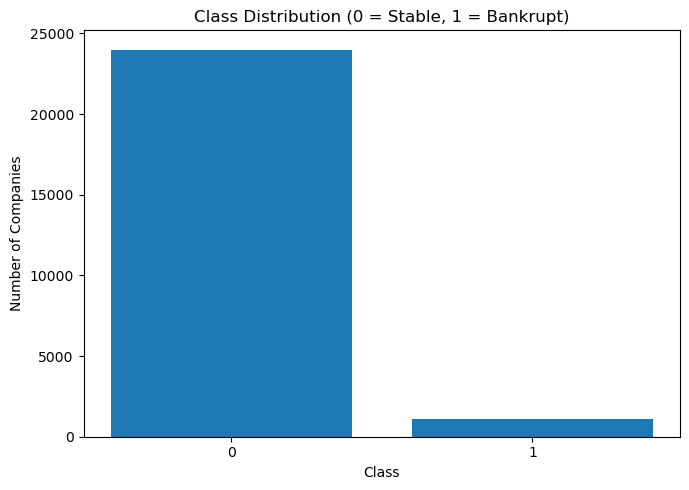

Plot saved: results\class_distribution.png


In [7]:
print_line("INITIAL DATA ANALYSIS")

print("\nTrain info:")
print(train_df.info())

print("\nMissing values per column (top-20):")
print(train_df.isna().sum().sort_values(ascending=False).head(20))

print("\nTarget variable check:")
print(train_df[TARGET_COL].value_counts(dropna=False))

plot_class_distribution(train_df[TARGET_COL])

## 8. Data preparation

In [8]:
print_line("DATA PREPARATION")

test_ids = test_df[ID_COL].copy()

X = train_df.drop(columns=[TARGET_COL], errors="ignore")
y = train_df[TARGET_COL].copy()

X_test = test_df.copy()

X = X.drop(columns=[ID_COL], errors="ignore")
X_test = X_test.drop(columns=[ID_COL], errors="ignore")

X = X.apply(pd.to_numeric, errors="coerce")
X_test = X_test.apply(pd.to_numeric, errors="coerce")
y = pd.to_numeric(y, errors="coerce")

print("X shape:", X.shape)
print("y shape:", y.shape)
print("X_test shape:", X_test.shape)

print("\nData types after conversion:")
print(X.dtypes.head())

print("\nMissing values in X:")
print(X.isna().sum().sum())

print("\nMissing values in X_test:")
print(X_test.isna().sum().sum())

possible_size_features, size_note = check_company_size_features(X.columns)
altman_df, altman_note = check_altman_z_score_availability(X.columns)


DATA PREPARATION
X shape: (25121, 65)
y shape: (25121,)
X_test shape: (12374, 65)

Data types after conversion:
forecasting period                              int64
net_profit_over_total_assets                  float64
total_liabilities_over_total_assets           float64
working_capital_over_total_assets             float64
current_assets_over_short_term_liabilities    float64
dtype: object

Missing values in X:
24806

Missing values in X_test:
11850

CHECKING COMPANY SIZE FEATURES
Found 55 possible company size features.
Saved: results\possible_size_features.csv
Saved: results\possible_size_features.xlsx

ALTMAN Z-SCORE AVAILABILITY CHECK
Saved: results\altman_z_score_availability.csv
Saved: results\altman_z_score_availability.xlsx
All feature groups for Altman Z-score potentially available.


## 9. Descriptive statistics

In [9]:
print_line("DESCRIPTIVE STATISTICS")

desc_stats = X.describe().T.reset_index()
desc_stats.columns = ["Feature", "Count", "Mean", "Std", "Min", "25%", "50%", "75%", "Max"]

print(desc_stats.head(10))

save_dataframe(desc_stats, "descriptive_statistics.csv")
save_excel(desc_stats, "descriptive_statistics.xlsx")


DESCRIPTIVE STATISTICS
                                             Feature    Count       Mean  \
0                                 forecasting period  25121.0   2.608574   
1                       net_profit_over_total_assets  25118.0   0.046883   
2                total_liabilities_over_total_assets  25118.0   0.611913   
3                  working_capital_over_total_assets  25118.0   0.098553   
4         current_assets_over_short_term_liabilities  25043.0   6.285753   
5  cash_plus_short_term_securities_plus_receivabl...  25064.0 -91.259359   
6                retained_earnings_over_total_assets  25118.0  -0.067728   
7                             EBIT_over_total_assets  25118.0   0.147535   
8        book_value_of_equity_over_total_liabilities  25072.0  15.153162   
9                            sales_over_total_assets  25114.0   2.905686   

            Std           Min        25%       50%        75%           Max  
0      1.063099  1.000000e+00   2.000000  3.000000   4.000000

## 10. Class means comparison

In [10]:
print_line("CLASS MEANS COMPARISON")

train_numeric_with_target = X.copy()
train_numeric_with_target[TARGET_COL] = y

class_means = train_numeric_with_target.groupby(TARGET_COL).mean().T.reset_index()
class_means.columns = ["Feature", "Mean_Class_0", "Mean_Class_1"]

class_means["Difference"] = class_means["Mean_Class_1"] - class_means["Mean_Class_0"]
class_means["AbsDifference"] = class_means["Difference"].abs()
class_means = class_means.sort_values("AbsDifference", ascending=False)

print(class_means.head(20))

save_dataframe(class_means, "class_means_comparison.csv")
save_excel(class_means, "class_means_comparison.xlsx")


CLASS MEANS COMPARISON
                                              Feature  Mean_Class_0  \
55                                    working_capital   7214.605694   
15  total_liabilities_times_365_over_gross_profit_...   2305.375072   
62        short_term_liabilities_times_365_over_sales    686.872401   
27  profit_on_operating_activities_over_financial_...   1076.539200   
32  current_liabilities_times_365_over_cost_of_pro...    598.981765   
47     inventory_times_365_over_cost_of_products_sold    285.270233   
44                   receivables_times_365_over_sales    348.924772   
43  rotation_receivables_plus_inventory_turnover_i...    408.787213   
60                               sales_over_inventory    330.016305   
5   cash_plus_short_term_securities_plus_receivabl...    -85.694003   
64                            sales_over_fixed_assets     74.390060   
54                 constant_capital_over_fixed_assets     24.475482   
53                           equity_over_fixed_assets

## 11. Correlation with target

In [11]:
print_line("CORRELATION WITH TARGET")

corr_df = train_numeric_with_target.corr(numeric_only=True)[[TARGET_COL]].reset_index()
corr_df.columns = ["Feature", "CorrelationWithClass"]
corr_df = corr_df[corr_df["Feature"] != TARGET_COL].copy()
corr_df["AbsCorrelation"] = corr_df["CorrelationWithClass"].abs()
corr_df = corr_df.sort_values("AbsCorrelation", ascending=False)

print(corr_df.head(20))

save_dataframe(corr_df, "correlation_with_target.csv")
save_excel(corr_df, "correlation_with_target.xlsx")


CORRELATION WITH TARGET
                                              Feature  CorrelationWithClass  \
29                          logarithm_of_total_assets             -0.045886   
2                 total_liabilities_over_total_assets              0.034960   
3                   working_capital_over_total_assets             -0.034581   
51           short_term_liabilities_over_total_assets              0.034397   
0                                  forecasting period              0.031805   
6                 retained_earnings_over_total_assets             -0.030944   
39                         profit_on_sales_over_sales             -0.027954   
25       equity_minus_share_capital_over_total_assets             -0.021372   
12           gross_profit_over_short_term_liabilities             -0.020385   
55                                    working_capital             -0.019007   
56       sales_minus_cost_of_products_sold_over_sales             -0.017916   
16  gross_profit_plus_depre

## 12. Feature selection: missing values, variance, multicollinearity

In [12]:
X_filtered, X_test_filtered, dropped_bad_features, feature_filter_report = remove_bad_features(X, X_test)
X_reduced, dropped_corr_features, high_corr_pairs, multicollinearity_report = analyze_multicollinearity(
    X_filtered,
    y,
    corr_df
)
X_test_reduced = X_test_filtered.drop(columns=dropped_corr_features, errors="ignore")
vif_df = calculate_vif_report(X_reduced)

selected_features = X_reduced.columns.tolist()
selected_features_df = pd.DataFrame({"SelectedFeature": selected_features})
save_dataframe(selected_features_df, "selected_features_after_multicollinearity.csv")
save_excel(selected_features_df, "selected_features_after_multicollinearity.xlsx")

print_line("FEATURE SELECTION SUMMARY")
print(f"Initial number of features: {X.shape[1]}")
print(f"After missing/constant/low-variance removal: {X_filtered.shape[1]}")
print(f"After multicollinearity removal: {X_reduced.shape[1]}")
print("Final feature set saved to selected_features_after_multicollinearity.csv/xlsx")


FEATURE SELECTION: MISSING VALUES AND NEAR-CONSTANT VARIABLES
Saved: results\missing_ratio_by_feature.csv
Saved: results\missing_ratio_by_feature.xlsx
Saved: results\feature_filter_report_missing_variance.csv
Saved: results\feature_filter_report_missing_variance.xlsx
Features before filtering: 65
Removed by missing/variance/constant: 0
Features after initial filtering: 65

MULTICOLLINEARITY CHECK
Saved: results\feature_correlation_matrix.csv
Saved: results\high_correlation_feature_pairs.csv
Saved: results\high_correlation_feature_pairs.xlsx
Saved: results\multicollinearity_removed_features.csv
Saved: results\multicollinearity_removed_features.xlsx
Feature pairs with |corr| >= 0.9: 45
Features removed due to high correlation: 24
Features after multicollinearity removal: 41

VIF MULTICOLLINEARITY ANALYSIS
Saved: results\vif_report.csv
Saved: results\vif_report.xlsx
Top-20 features by VIF:
                                              Feature        VIF
5                             sale

## 13. Robustness check: three random train/validation splits

In [13]:
print_line("DATA SPLITTING - MULTIPLE RANDOM SEEDS ROBUSTNESS CHECK")

split_results = []

for rs in RANDOM_STATES:

    print_line(f"TRAIN-TEST SPLIT WITH RANDOM_STATE={rs}")

    X_train, X_valid, y_train, y_valid = train_test_split(
        X_reduced,
        y,
        test_size=0.2,
        random_state=rs,
        stratify=y
    )

    print("X_train shape:", X_train.shape)
    print("X_valid shape:", X_valid.shape)

    scale_pos_weight = len(y_train[y_train == 0]) / len(y_train[y_train == 1])
    print(f"scale_pos_weight: {scale_pos_weight:.4f}")

    # Run all three models for each split
    models_for_split = {
        "Logistic Regression": build_model(),
        "Random Forest": build_random_forest_model(),
        "XGBoost": build_xgboost_model(scale_pos_weight)
    }

    for model_name, current_model in models_for_split.items():
        print_line(f"TRAINING: {model_name} (seed={rs})")
        current_model.fit(X_train, y_train)

        y_pred_temp = current_model.predict(X_valid)
        y_prob_temp = current_model.predict_proba(X_valid)[:, 1]

        split_results.append({
            "RandomState": rs,
            "Model": model_name,
            "Accuracy": accuracy_score(y_valid, y_pred_temp),
            "Precision": precision_score(y_valid, y_pred_temp, zero_division=0),
            "Recall": recall_score(y_valid, y_pred_temp, zero_division=0),
            "F1-score": f1_score(y_valid, y_pred_temp, zero_division=0),
            "ROC-AUC": roc_auc_score(y_valid, y_prob_temp)
        })

split_results_df = pd.DataFrame(split_results)

save_dataframe(split_results_df, "multiple_split_results.csv")
save_excel(split_results_df, "multiple_split_results.xlsx")

print("\n=== ROBUSTNESS CHECK - ALL MODELS ON 3 RANDOM SEEDS ===")
print(split_results_df.to_string())


DATA SPLITTING - MULTIPLE RANDOM SEEDS ROBUSTNESS CHECK

TRAIN-TEST SPLIT WITH RANDOM_STATE=42
X_train shape: (20096, 41)
X_valid shape: (5025, 41)
scale_pos_weight: 21.3041

TRAINING: Logistic Regression (seed=42)

TRAINING: Random Forest (seed=42)

TRAINING: XGBoost (seed=42)

TRAIN-TEST SPLIT WITH RANDOM_STATE=123
X_train shape: (20096, 41)
X_valid shape: (5025, 41)
scale_pos_weight: 21.3041

TRAINING: Logistic Regression (seed=123)

TRAINING: Random Forest (seed=123)

TRAINING: XGBoost (seed=123)

TRAIN-TEST SPLIT WITH RANDOM_STATE=999
X_train shape: (20096, 41)
X_valid shape: (5025, 41)
scale_pos_weight: 21.3041

TRAINING: Logistic Regression (seed=999)

TRAINING: Random Forest (seed=999)

TRAINING: XGBoost (seed=999)
Saved: results\multiple_split_results.csv
Saved: results\multiple_split_results.xlsx

=== ROBUSTNESS CHECK - ALL MODELS ON 3 RANDOM SEEDS ===
   RandomState                Model  Accuracy  Precision    Recall  F1-score   ROC-AUC
0           42  Logistic Regression  

## 14. Final train/validation split (random_state = 42)

In [14]:
# After multiple splits - use seed=42 as standard for the rest of analysis
print_line("FINAL TRAIN-VALID SPLIT (random_state=42)")

X_train, X_valid, y_train, y_valid = train_test_split(
    X_reduced,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

scale_pos_weight = len(y_train[y_train == 0]) / len(y_train[y_train == 1])

print(f"scale_pos_weight: {scale_pos_weight:.4f}")


FINAL TRAIN-VALID SPLIT (random_state=42)
scale_pos_weight: 21.3041


## 15. Logistic Regression: training and evaluation


MODEL TRAINING
Model successfully trained.

MODEL EVALUATION
Accuracy : 0.6613
Precision: 0.0748
Recall   : 0.5778
F1-score : 0.1325
ROC-AUC  : 0.6656

Confusion Matrix:
[[3193 1607]
 [  95  130]]

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.67      0.79      4800
           1       0.07      0.58      0.13       225

    accuracy                           0.66      5025
   macro avg       0.52      0.62      0.46      5025
weighted avg       0.93      0.66      0.76      5025

Saved: results\model_metrics.csv
Saved: results\model_metrics.xlsx
Saved: results\confusion_matrix.csv
Saved: results\confusion_matrix.xlsx


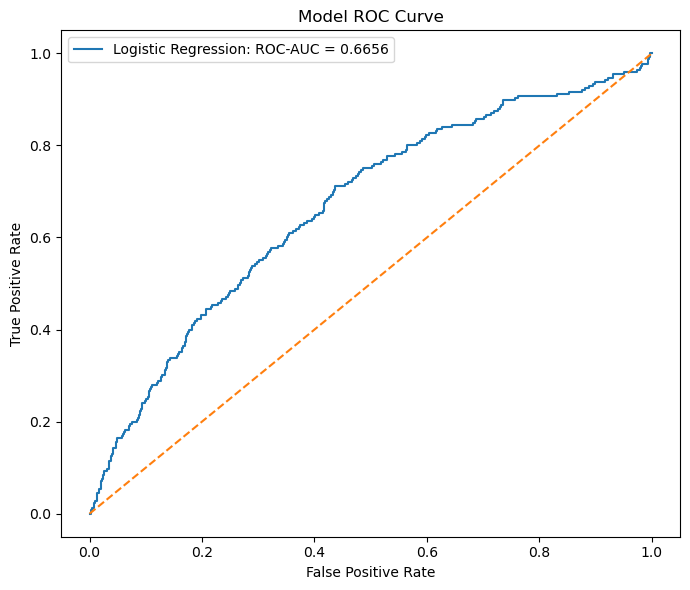

Plot saved: results\roc_curve_logistic_regression.png


In [15]:
print_line("MODEL TRAINING")

model = build_model()
model.fit(X_train, y_train)

print("Model successfully trained.")

print_line("MODEL EVALUATION")

y_pred = model.predict(X_valid)
y_prob = model.predict_proba(X_valid)[:, 1]

accuracy = accuracy_score(y_valid, y_pred)
precision = precision_score(y_valid, y_pred, zero_division=0)
recall = recall_score(y_valid, y_pred, zero_division=0)
f1 = f1_score(y_valid, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_valid, y_prob)
cm = confusion_matrix(y_valid, y_pred)
report = classification_report(y_valid, y_pred, zero_division=0)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(report)

metrics_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
    "Value": [accuracy, precision, recall, f1, roc_auc]
})

save_dataframe(metrics_df, "model_metrics.csv")
save_excel(metrics_df, "model_metrics.xlsx")

cm_df = pd.DataFrame(cm, index=["Actual_0", "Actual_1"], columns=["Predicted_0", "Predicted_1"])
save_dataframe(cm_df.reset_index(), "confusion_matrix.csv")
save_excel(cm_df.reset_index(), "confusion_matrix.xlsx")

plot_roc_curve(y_valid, y_prob, model_name="Logistic Regression", file_name="roc_curve_logistic_regression.png")

## 16. Logistic Regression coefficients


FEATURE IMPORTANCE ANALYSIS

Top-20 most important features:
                                           Feature  Coefficient  \
21               profit_on_sales_over_total_assets    -7.558744   
5                          sales_over_total_assets     3.403107   
14    equity_minus_share_capital_over_total_assets    -3.172568   
8        gross_profit_plus_depreciation_over_sales    -2.333220   
6                         equity_over_total_assets    -1.765610   
4              retained_earnings_over_total_assets     1.586947   
13       gross_profit_in_3_years_over_total_assets    -1.490495   
40               sales_over_short_term_liabilities    -1.469994   
29  inventory_times_365_over_cost_of_products_sold    -1.455825   
19           gross_profit_plus_interest_over_sales     1.413660   
27                receivables_times_365_over_sales    -1.316159   
35                     total_costs_overtotal_sales    -1.219720   
2              total_liabilities_over_total_assets    -0.948618   


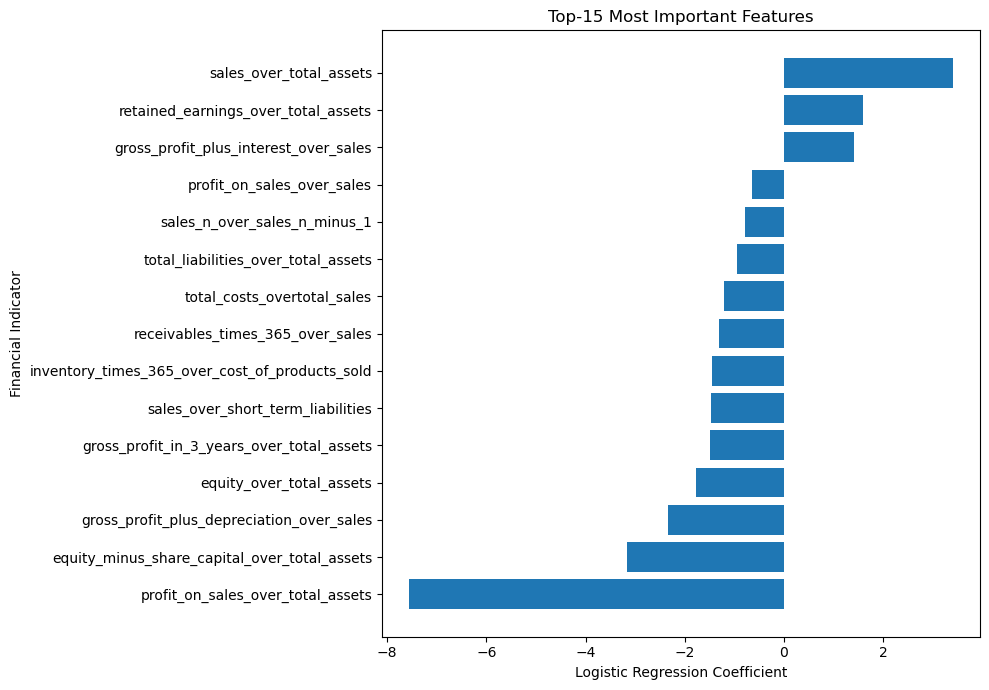

Plot saved: results\top_coefficients.png


In [16]:
print_line("FEATURE IMPORTANCE ANALYSIS")

logreg_model = model.named_steps["logreg"]
coefficients = logreg_model.coef_[0]

coef_df = pd.DataFrame({
    "Feature": X_reduced.columns,
    "Coefficient": coefficients
})

coef_df["AbsCoefficient"] = coef_df["Coefficient"].abs()
coef_df["Interpretation"] = np.where(
    coef_df["Coefficient"] > 0,
    "Increases bankruptcy probability",
    "Decreases bankruptcy probability"
)

coef_df = coef_df.sort_values("AbsCoefficient", ascending=False)

print("\nTop-20 most important features:")
print(coef_df.head(20))

retained_features = coef_df[
    coef_df["Feature"].str.contains(
        "retained",
        case=False,
        na=False
    )
]

if not retained_features.empty:
    print("\nRetained earnings related features:")
    print(retained_features)

save_dataframe(coef_df, "feature_coefficients.csv")
save_excel(coef_df, "feature_coefficients.xlsx")

plot_top_coefficients(coef_df, top_n=15)

## 17. Random Forest and XGBoost, model comparison


TRAINING ADDITIONAL MODELS

TRAINING: Random Forest

MODEL EVALUATION: Random Forest
Accuracy  : 0.9616
Precision : 0.8200
Recall    : 0.1822
F1-score  : 0.2982
ROC-AUC   : 0.8944

Confusion Matrix:
[[4791    9]
 [ 184   41]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      1.00      0.98      4800
           1       0.82      0.18      0.30       225

    accuracy                           0.96      5025
   macro avg       0.89      0.59      0.64      5025
weighted avg       0.96      0.96      0.95      5025


FEATURE IMPORTANCE: Random Forest
                                              Feature  Importance
15  profit_on_operating_activities_over_financial_...    0.100595
13          gross_profit_in_3_years_over_total_assets    0.068510
8           gross_profit_plus_depreciation_over_sales    0.043086
4                 retained_earnings_over_total_assets    0.042439
23                         profit_on_sales_over_sales    

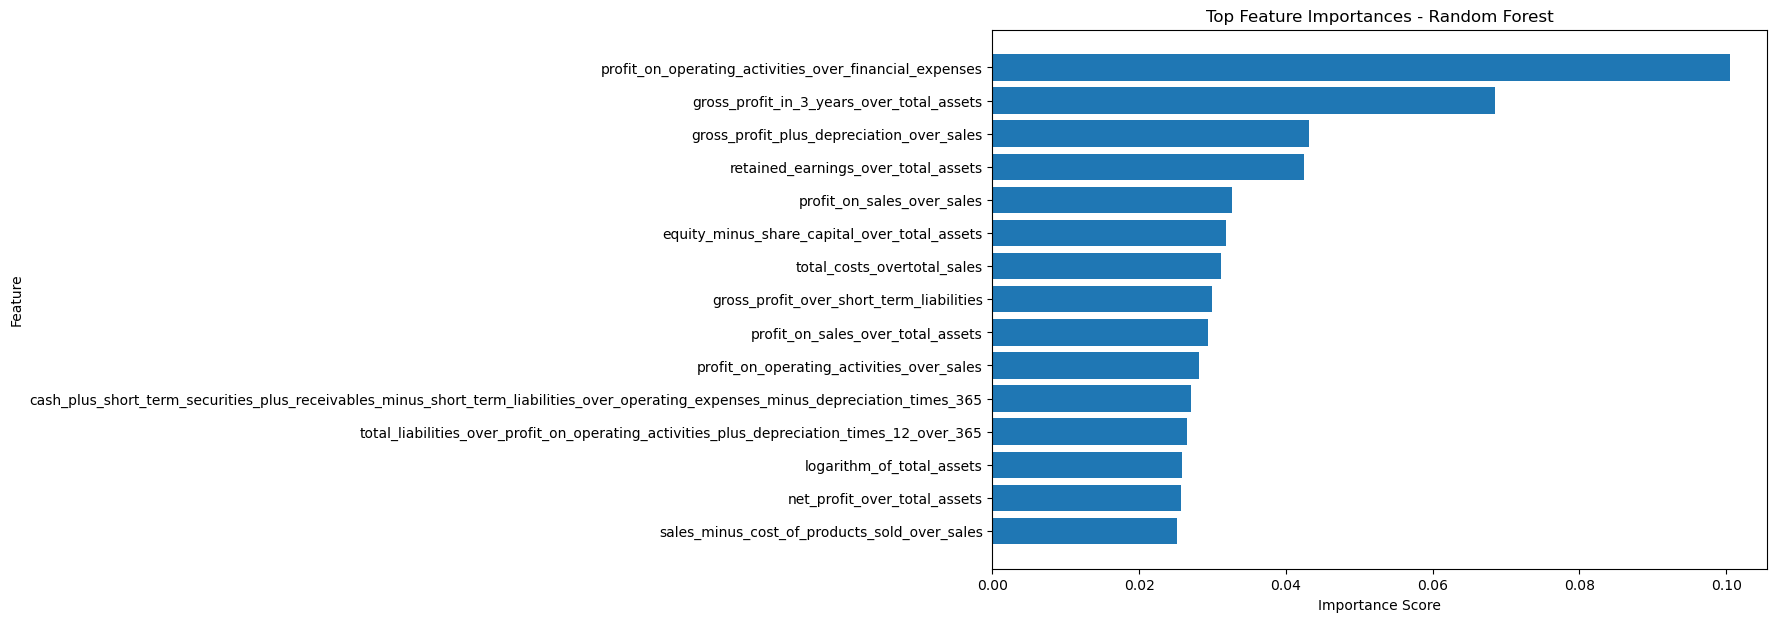

Plot saved: results\feature_importance_plot_random_forest.png
Saved: results\feature_importance_random_forest.csv
Saved: results\feature_importance_random_forest.xlsx

TRAINING: XGBoost

MODEL EVALUATION: XGBoost
Accuracy  : 0.9313
Precision : 0.3585
Recall    : 0.6756
F1-score  : 0.4684
ROC-AUC   : 0.9280

Confusion Matrix:
[[4528  272]
 [  73  152]]

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.94      0.96      4800
           1       0.36      0.68      0.47       225

    accuracy                           0.93      5025
   macro avg       0.67      0.81      0.72      5025
weighted avg       0.96      0.93      0.94      5025


FEATURE IMPORTANCE: XGBoost
                                              Feature  Importance
13          gross_profit_in_3_years_over_total_assets    0.079880
15  profit_on_operating_activities_over_financial_...    0.059646
7            gross_profit_over_short_term_liabilities    0.054042
8 

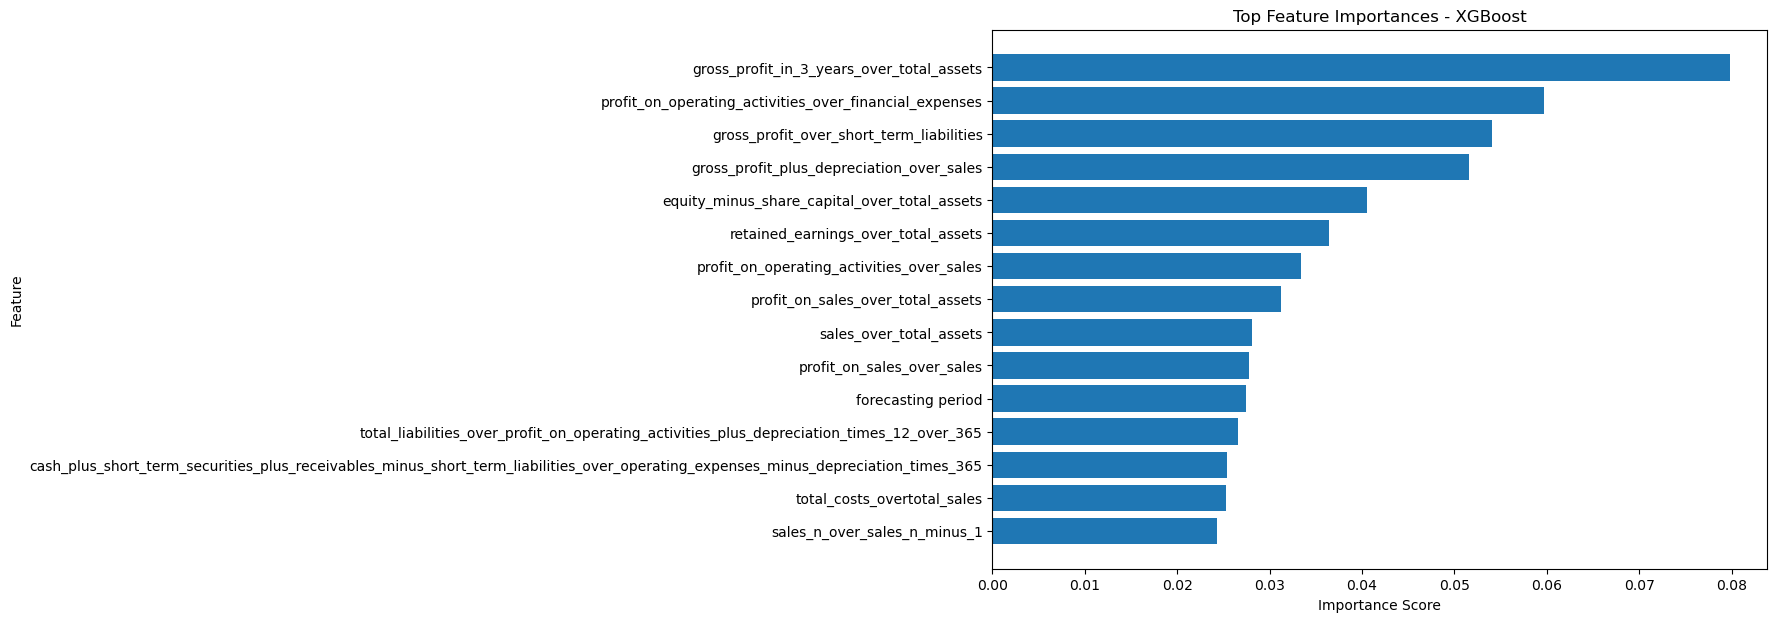

Plot saved: results\feature_importance_plot_xgboost.png
Saved: results\feature_importance_xgboost.csv
Saved: results\feature_importance_xgboost.xlsx

MODEL COMPARISON
                 Model  Accuracy  Precision    Recall  F1-score   ROC-AUC
2              XGBoost  0.931343   0.358491  0.675556  0.468413  0.927959
1        Random Forest  0.961592   0.820000  0.182222  0.298182  0.894403
0  Logistic Regression  0.661294   0.074842  0.577778  0.132518  0.665588
Saved: results\models_comparison_metrics.csv
Saved: results\models_comparison_metrics.xlsx


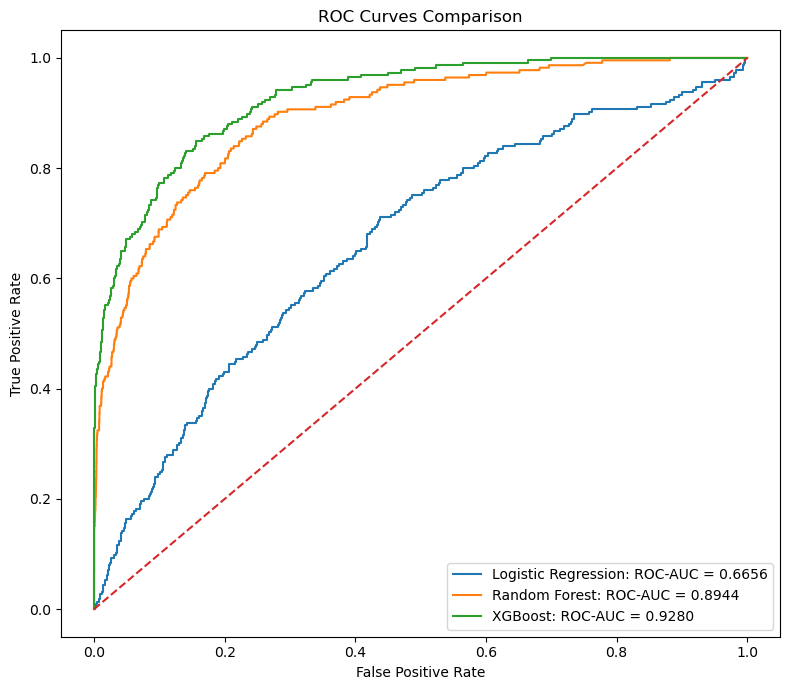

Plot saved: results\roc_curves_all_models.png
Best model by ROC-AUC: XGBoost


In [17]:
print_line("TRAINING ADDITIONAL MODELS")

models = {
    "Logistic Regression": model,
    "Random Forest": build_random_forest_model(),
    "XGBoost": build_xgboost_model(scale_pos_weight)
}


model_metrics = []
model_probabilities = {"Logistic Regression": y_prob}
model_reports = {}
model_confusion_matrices = {}

model_metrics.append({
    "Model": "Logistic Regression",
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-score": f1,
    "ROC-AUC": roc_auc
})
model_reports["Logistic Regression"] = report
model_confusion_matrices["Logistic Regression"] = cm

for model_name, current_model in models.items():
    if model_name == "Logistic Regression":
        continue
    print_line(f"TRAINING: {model_name}")
    current_model.fit(X_train, y_train)
    metrics, current_cm, current_report, current_prob = evaluate_model(
        model_name,
        current_model,
        X_valid,
        y_valid
    )
    model_metrics.append(metrics)
    model_probabilities[model_name] = current_prob
    model_reports[model_name] = current_report
    model_confusion_matrices[model_name] = current_cm
    get_feature_importance(model_name, current_model, X_reduced.columns, X_valid, y_valid)

models_comparison_df = pd.DataFrame(model_metrics).sort_values("ROC-AUC", ascending=False)
print_line("MODEL COMPARISON")
print(models_comparison_df)

save_dataframe(models_comparison_df, "models_comparison_metrics.csv")
save_excel(models_comparison_df, "models_comparison_metrics.xlsx")

plot_all_roc_curves(y_valid, model_probabilities)

best_model_name = models_comparison_df.iloc[0]["Model"]
best_model = models[best_model_name]
print(f"Best model by ROC-AUC: {best_model_name}")

## 18. Stratified 5-fold cross-validation

In [18]:
print_line(f"STRATIFIED {N_SPLITS_CV}-FOLD CROSS-VALIDATION")

cv_results = []
skf = StratifiedKFold(n_splits=N_SPLITS_CV, shuffle=True, random_state=RANDOM_STATE)

cv_model_configs = ["Logistic Regression", "Random Forest", "XGBoost"]

for model_name in cv_model_configs:
    print(f"\n--- Cross-validating: {model_name} ---")
    fold_metrics = {
        "Accuracy": [], "Precision": [], "Recall": [],
        "F1-score": [], "ROC-AUC": []
    }

    for fold_num, (train_idx, val_idx) in enumerate(skf.split(X_reduced, y), start=1):
        X_fold_train = X_reduced.iloc[train_idx]
        X_fold_val = X_reduced.iloc[val_idx]
        y_fold_train = y.iloc[train_idx]
        y_fold_val = y.iloc[val_idx]

        if model_name == "Logistic Regression":
            current_model = build_model()
        elif model_name == "Random Forest":
            current_model = build_random_forest_model()
        elif model_name == "XGBoost":
            spw = len(y_fold_train[y_fold_train == 0]) / len(y_fold_train[y_fold_train == 1])
            current_model = build_xgboost_model(spw)

        current_model.fit(X_fold_train, y_fold_train)

        y_pred_cv = current_model.predict(X_fold_val)
        y_prob_cv = current_model.predict_proba(X_fold_val)[:, 1]

        fold_metrics["Accuracy"].append(accuracy_score(y_fold_val, y_pred_cv))
        fold_metrics["Precision"].append(precision_score(y_fold_val, y_pred_cv, zero_division=0))
        fold_metrics["Recall"].append(recall_score(y_fold_val, y_pred_cv, zero_division=0))
        fold_metrics["F1-score"].append(f1_score(y_fold_val, y_pred_cv, zero_division=0))
        fold_metrics["ROC-AUC"].append(roc_auc_score(y_fold_val, y_prob_cv))

        print(f"  Fold {fold_num}: ROC-AUC={fold_metrics['ROC-AUC'][-1]:.4f}, "
              f"F1={fold_metrics['F1-score'][-1]:.4f}")

    cv_results.append({
        "Model": model_name,
        "Accuracy (mean)": np.mean(fold_metrics["Accuracy"]),
        "Accuracy (std)": np.std(fold_metrics["Accuracy"]),
        "Precision (mean)": np.mean(fold_metrics["Precision"]),
        "Precision (std)": np.std(fold_metrics["Precision"]),
        "Recall (mean)": np.mean(fold_metrics["Recall"]),
        "Recall (std)": np.std(fold_metrics["Recall"]),
        "F1-score (mean)": np.mean(fold_metrics["F1-score"]),
        "F1-score (std)": np.std(fold_metrics["F1-score"]),
        "ROC-AUC (mean)": np.mean(fold_metrics["ROC-AUC"]),
        "ROC-AUC (std)": np.std(fold_metrics["ROC-AUC"])
    })

    print(f"  -> MEAN: ROC-AUC = {np.mean(fold_metrics['ROC-AUC']):.4f} "
          f"± {np.std(fold_metrics['ROC-AUC']):.4f}")
    print(f"  -> MEAN: F1-score = {np.mean(fold_metrics['F1-score']):.4f} "
          f"± {np.std(fold_metrics['F1-score']):.4f}")

cv_results_df = pd.DataFrame(cv_results)

for col in cv_results_df.columns:
    if col != "Model":
        cv_results_df[col] = cv_results_df[col].round(4)

print_line(f"FINAL {N_SPLITS_CV}-FOLD CV RESULTS SUMMARY")
print(cv_results_df.to_string())

save_dataframe(cv_results_df, "cross_validation_results.csv")
save_excel(cv_results_df, "cross_validation_results.xlsx")

# Compact summary table for the diploma
cv_compact_df = cv_results_df[["Model", "ROC-AUC (mean)", "ROC-AUC (std)",
                                "F1-score (mean)", "F1-score (std)",
                                "Precision (mean)", "Recall (mean)"]].copy()
save_dataframe(cv_compact_df, "cross_validation_summary.csv")
save_excel(cv_compact_df, "cross_validation_summary.xlsx")


STRATIFIED 5-FOLD CROSS-VALIDATION

--- Cross-validating: Logistic Regression ---
  Fold 1: ROC-AUC=0.6860, F1=0.1456
  Fold 2: ROC-AUC=0.6728, F1=0.1312
  Fold 3: ROC-AUC=0.6982, F1=0.1457
  Fold 4: ROC-AUC=0.6314, F1=0.1148
  Fold 5: ROC-AUC=0.6768, F1=0.1319
  -> MEAN: ROC-AUC = 0.6730 ± 0.0226
  -> MEAN: F1-score = 0.1339 ± 0.0114

--- Cross-validating: Random Forest ---
  Fold 1: ROC-AUC=0.9099, F1=0.2930
  Fold 2: ROC-AUC=0.8819, F1=0.2667
  Fold 3: ROC-AUC=0.9031, F1=0.2547
  Fold 4: ROC-AUC=0.9138, F1=0.3719
  Fold 5: ROC-AUC=0.9141, F1=0.3262
  -> MEAN: ROC-AUC = 0.9046 ± 0.0120
  -> MEAN: F1-score = 0.3025 ± 0.0425

--- Cross-validating: XGBoost ---
  Fold 1: ROC-AUC=0.9341, F1=0.5031
  Fold 2: ROC-AUC=0.9247, F1=0.4451
  Fold 3: ROC-AUC=0.9260, F1=0.4532
  Fold 4: ROC-AUC=0.9378, F1=0.4798
  Fold 5: ROC-AUC=0.9331, F1=0.4802
  -> MEAN: ROC-AUC = 0.9311 ± 0.0050
  -> MEAN: F1-score = 0.4723 ± 0.0208

FINAL 5-FOLD CV RESULTS SUMMARY
                 Model  Accuracy (mean)  Ac

## 19. Classification reports and confusion matrices

In [19]:
reports_text = []
for model_name, model_report in model_reports.items():
    reports_text.append(f"\n{'=' * 70}\n{model_name}\n{'=' * 70}\n{model_report}\n")
save_text("\n".join(reports_text), "classification_reports_all_models.txt")

for model_name, current_cm in model_confusion_matrices.items():
    safe_name = model_name.lower().replace(" ", "_").replace("-", "_")
    current_cm_df = pd.DataFrame(current_cm, index=["Actual_0", "Actual_1"], columns=["Predicted_0", "Predicted_1"])
    save_dataframe(current_cm_df.reset_index(), f"confusion_matrix_{safe_name}.csv")
    save_excel(current_cm_df.reset_index(), f"confusion_matrix_{safe_name}.xlsx")

Saved: results\classification_reports_all_models.txt
Saved: results\confusion_matrix_logistic_regression.csv
Saved: results\confusion_matrix_logistic_regression.xlsx
Saved: results\confusion_matrix_random_forest.csv
Saved: results\confusion_matrix_random_forest.xlsx
Saved: results\confusion_matrix_xgboost.csv
Saved: results\confusion_matrix_xgboost.xlsx


## 20. Final model and test predictions

In [20]:
print_line("FINAL MODEL TRAINED ON ALL TRAIN DATA")

final_model = models[best_model_name]
final_model.fit(X_reduced, y)

print(f"Final model ({best_model_name}) trained on full train.csv")

print_line("TEST PREDICTIONS")

test_pred = final_model.predict(X_test_reduced)
test_prob = get_probabilities(final_model, X_test_reduced)

submission = pd.DataFrame({
    ID_COL: test_ids,
    TARGET_COL: test_pred
})

submission_prob = pd.DataFrame({
    ID_COL: test_ids,
    "probability_of_bankruptcy": test_prob
})

print("\nFirst 10 rows of submission:")
print(submission.head(10))

print("\nFirst 10 rows of submission_prob:")
print(submission_prob.head(10))

save_dataframe(submission, "submission.csv")
save_excel(submission, "submission.xlsx")

save_dataframe(submission_prob, "submission_probabilities.csv")
save_excel(submission_prob, "submission_probabilities.xlsx")

print_line("ADDITIONAL SUBMISSIONS PER MODEL")
for model_name, current_model in models.items():
    print(f"Preparing submission for model: {model_name}")
    current_final_model = current_model
    current_final_model.fit(X_reduced, y)
    current_test_pred = current_final_model.predict(X_test_reduced)
    current_test_prob = get_probabilities(current_final_model, X_test_reduced)

    safe_name = model_name.lower().replace(" ", "_").replace("-", "_")
    current_submission = pd.DataFrame({ID_COL: test_ids, TARGET_COL: current_test_pred})
    current_submission_prob = pd.DataFrame({ID_COL: test_ids, "probability_of_bankruptcy": current_test_prob})

    save_dataframe(current_submission, f"submission_{safe_name}.csv")
    save_dataframe(current_submission_prob, f"submission_probabilities_{safe_name}.csv")


FINAL MODEL TRAINED ON ALL TRAIN DATA
Final model (XGBoost) trained on full train.csv

TEST PREDICTIONS

First 10 rows of submission:
      id  class
0  25121      0
1  25122      0
2  25123      0
3  25124      0
4  25125      0
5  25126      0
6  25127      0
7  25128      0
8  25129      0
9  25130      0

First 10 rows of submission_prob:
      id  probability_of_bankruptcy
0  25121                   0.092515
1  25122                   0.290259
2  25123                   0.159245
3  25124                   0.046386
4  25125                   0.008653
5  25126                   0.137925
6  25127                   0.135680
7  25128                   0.008561
8  25129                   0.008837
9  25130                   0.024836
Saved: results\submission.csv
Saved: results\submission.xlsx
Saved: results\submission_probabilities.csv
Saved: results\submission_probabilities.xlsx

ADDITIONAL SUBMISSIONS PER MODEL
Preparing submission for model: Logistic Regression
Saved: results\submiss

## 21. Interpretation of Logistic Regression coefficients

In [21]:
print_line("RESULTS INTERPRETATION")

top_positive = coef_df[coef_df["Coefficient"] > 0].head(10)
top_negative = coef_df[coef_df["Coefficient"] < 0].head(10)

print("Factors that most strongly INCREASE bankruptcy probability:")
print(top_positive[["Feature", "Coefficient"]])

print("\nFactors that most strongly DECREASE bankruptcy probability:")
print(top_negative[["Feature", "Coefficient"]])


RESULTS INTERPRETATION
Factors that most strongly INCREASE bankruptcy probability:
                                              Feature  Coefficient
5                             sales_over_total_assets     3.403107
4                 retained_earnings_over_total_assets     1.586947
19              gross_profit_plus_interest_over_sales     1.413660
11                     inventory_times_365_over_sales     0.426736
18            total_liabilities_minus_cash_over_sales     0.248437
31                 constant_capital_over_fixed_assets     0.207824
1                        net_profit_over_total_assets     0.131533
0                                  forecasting period     0.090935
26          profit_on_operating_activities_over_sales     0.071999
9   total_liabilities_times_365_over_gross_profit_...     0.071419

Factors that most strongly DECREASE bankruptcy probability:
                                           Feature  Coefficient
21               profit_on_sales_over_total_assets    

## 22. Summary of the robustness check

In [22]:
print_line("MULTIPLE SPLIT SUMMARY - ROBUSTNESS ACROSS SEEDS")

summary_split = (
    split_results_df
    .groupby("Model")[["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]]
    .agg(["mean", "std"])
    .round(4)
    .reset_index()
)

print(summary_split)

save_dataframe(summary_split, "multiple_split_summary.csv")


MULTIPLE SPLIT SUMMARY - ROBUSTNESS ACROSS SEEDS
                 Model Accuracy         Precision          Recall          \
                           mean     std      mean     std    mean     std   
0  Logistic Regression   0.6641  0.0103    0.0777  0.0043  0.5985  0.0563   
1        Random Forest   0.9613  0.0010    0.7821  0.0548  0.1896  0.0128   
2              XGBoost   0.9285  0.0040    0.3499  0.0196  0.6948  0.0454   

  F1-score         ROC-AUC          
      mean     std    mean     std  
0   0.1375  0.0082  0.6773  0.0283  
1   0.3051  0.0187  0.9022  0.0120  
2   0.4652  0.0256  0.9283  0.0166  
Saved: results\multiple_split_summary.csv


## 23. Threshold selection (XGBoost)

In [23]:
print_line("THRESHOLD SELECTION AND BUSINESS COST TRADE-OFF (XGBoost)")

spw_thr = len(y_train[y_train == 0]) / len(y_train[y_train == 1])
xgb_threshold_model = build_xgboost_model(spw_thr)
xgb_threshold_model.fit(X_train, y_train)

xgb_proba = xgb_threshold_model.predict_proba(X_valid)[:, 1]

threshold_list = [0.3, 0.4, 0.5, 0.6, 0.7]
threshold_rows = []
for t in threshold_list:
    y_pred_t = (xgb_proba >= t).astype(int)
    threshold_rows.append({
        "Threshold": t,
        "Precision": round(precision_score(y_valid, y_pred_t, zero_division=0), 3),
        "Recall":    round(recall_score(y_valid, y_pred_t, zero_division=0), 3),
        "F1-score":  round(f1_score(y_valid, y_pred_t, zero_division=0), 3),
    })

threshold_table = pd.DataFrame(threshold_rows)
print(threshold_table.to_string(index=False))

save_dataframe(threshold_table, "xgboost_threshold_tradeoff.csv")
save_excel(threshold_table, "xgboost_threshold_tradeoff.xlsx")


THRESHOLD SELECTION AND BUSINESS COST TRADE-OFF (XGBoost)
 Threshold  Precision  Recall  F1-score
       0.3      0.211   0.831     0.336
       0.4      0.276   0.742     0.402
       0.5      0.358   0.676     0.468
       0.6      0.478   0.591     0.529
       0.7      0.634   0.538     0.582
Saved: results\xgboost_threshold_tradeoff.csv
Saved: results\xgboost_threshold_tradeoff.xlsx


In [24]:
print_line("ANALYSIS COMPLETED - RESULTS SAVED TO results/ DIRECTORY")
print(f"All output files saved in: {RESULTS_DIR}/")


ANALYSIS COMPLETED - RESULTS SAVED TO results/ DIRECTORY
All output files saved in: results/
